In [93]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from utils_survey_analysis import *
import ipywidgets as widgets
from IPython.display import display
%matplotlib inline

In [36]:
    base_csv = "data/survey/data-base.csv"
    personnes_csv = "data/survey/data-personnes.csv"
    photos_csv = "data/survey/data-photos.csv"

In [37]:
df = import_and_merge_data_base(base_csv, personnes_csv, photos_csv)
df = df[df['job'] == 6]
df = df[df['postal_code'].between(69000, 70000, inclusive='neither')]

In [87]:
categories = ['gender', 'electric_bike', 'bike_use_frequency','bike_ownership', 'type','green', 'nbr_lane', "speed"]

In [89]:
for cat in categories:
    print(f"\n--- Analyse globale par : {cat} ---")
    global_stats = df.groupby(cat)['note'].agg(
        Moyenne='mean',
        Écart_type='std',
        Nombre_évaluations='count'
    ).reset_index()
    print(global_stats)


--- Analyse globale par : gender ---
   gender   Moyenne  Écart_type  Nombre_évaluations
0       0  3.263529    1.245472                 850
1       1  3.374332    1.227394                1122
2       2  2.941176    1.347077                  34

--- Analyse globale par : electric_bike ---
   electric_bike   Moyenne  Écart_type  Nombre_évaluations
0          False  3.306574    1.257440                1445
1           True  3.354724    1.189545                 561

--- Analyse globale par : bike_use_frequency ---
   bike_use_frequency   Moyenne  Écart_type  Nombre_évaluations
0                   0  3.067227    1.246902                 119
1                   1  3.153846    1.214999                 221
2                   2  3.221289    1.278076                 357
3                   3  3.271493    1.264750                 442
4                   4  3.462514    1.199274                 867

--- Analyse globale par : bike_ownership ---
   bike_ownership   Moyenne  Écart_type  Nombre_éval

In [90]:
for cat in categories:
    print(f"\n--- Note moyenne par photo selon : {cat} (Aperçu) ---")
    photo_cat_pivot = df.pivot_table(
        index='id_photo',
        columns=cat,
        values='note',
        aggfunc='mean'
    )
    print(photo_cat_pivot.head(10))


--- Note moyenne par photo selon : gender (Aperçu) ---
gender       0         1    2
id_photo                     
1         4.62  4.636364  4.5
2         4.16  4.151515  3.5
3         3.06  3.196970  3.5
4         2.46  2.515152  1.5
5         3.98  4.060606  1.5
6         3.96  3.757576  3.5
7         2.14  2.409091  1.5
8         2.84  3.045455  2.5
9         3.80  4.045455  3.0
10        3.02  3.121212  3.0

--- Note moyenne par photo selon : electric_bike (Aperçu) ---
electric_bike     False     True 
id_photo                         
1              4.623529  4.636364
2              4.070588  4.333333
3              3.105882  3.242424
4              2.400000  2.666667
5              3.941176  4.090909
6              3.905882  3.666667
7              2.211765  2.454545
8              2.894118  3.090909
9              3.952941  3.848485
10             3.082353  3.060606

--- Note moyenne par photo selon : bike_use_frequency (Aperçu) ---
bike_use_frequency         0         1       

In [91]:
for cat in categories:
    clean_df = df.dropna(subset=['note', cat])
    groups = [group['note'].values for name, group in clean_df.groupby(cat)]

    if len(groups) == 2:
        stat, p_value = stats.ttest_ind(groups[0], groups[1], nan_policy='omit')
        print(f"Test t de Student pour {cat} -> p-value : {p_value:.5f}")
    elif len(groups) > 2:
        stat, p_value = stats.f_oneway(*groups)
        print(f"ANOVA (Test F) pour {cat} -> p-value : {p_value:.5f}")
    else:
        print(f"Pas assez de groupes pour {cat}")

ANOVA (Test F) pour gender -> p-value : 0.02858
Test t de Student pour electric_bike -> p-value : 0.43471
ANOVA (Test F) pour bike_use_frequency -> p-value : 0.00010
Test t de Student pour bike_ownership -> p-value : 0.07743
ANOVA (Test F) pour type -> p-value : 0.00000
ANOVA (Test F) pour green -> p-value : 0.00000
ANOVA (Test F) pour nbr_lane -> p-value : 0.00000
ANOVA (Test F) pour speed -> p-value : 0.00000


In [59]:
def heat_map(variable, id_photo_val = "all"):
    # 1. Calcul de la moyenne des notes pour chaque modalité
    if id_photo_val == "all":
        df_filtered = df.copy()
    else:
        df_filtered = df[df['id_photo'] == id_photo_val]
    means = df_filtered.groupby(variable)['note'].mean()

    # 2. Création de la matrice de différences (Moyenne_i - Moyenne_j)
    diff_matrix = pd.DataFrame(
        np.subtract.outer(means.values, means.values),
        index=means.index,
        columns=means.index
    )

    # 3. Affichage de la Heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        diff_matrix,
        annot=True,          # Affiche la valeur de la différence dans la case
        cmap='coolwarm',
        center=0,
        fmt=".2f",
        cbar_kws={'label': 'Différence de note moyenne (Ligne - Colonne)'}
    )
    plt.title(f"Matrice des différences de notes moyennes\npar '{variable}'")
    plt.xlabel(f"Modalité ({variable})")
    plt.ylabel(f"Modalité ({variable})")
    plt.tight_layout()
    plt.show()

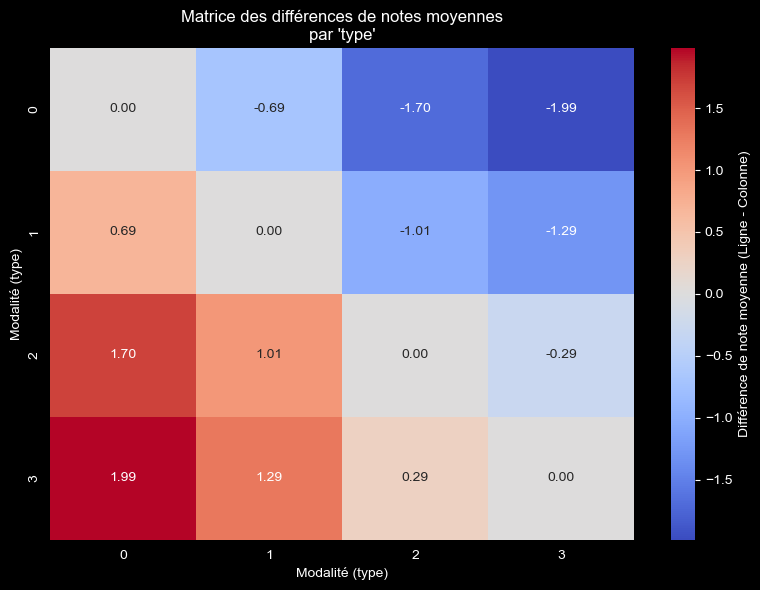

In [61]:
heat_map("type")

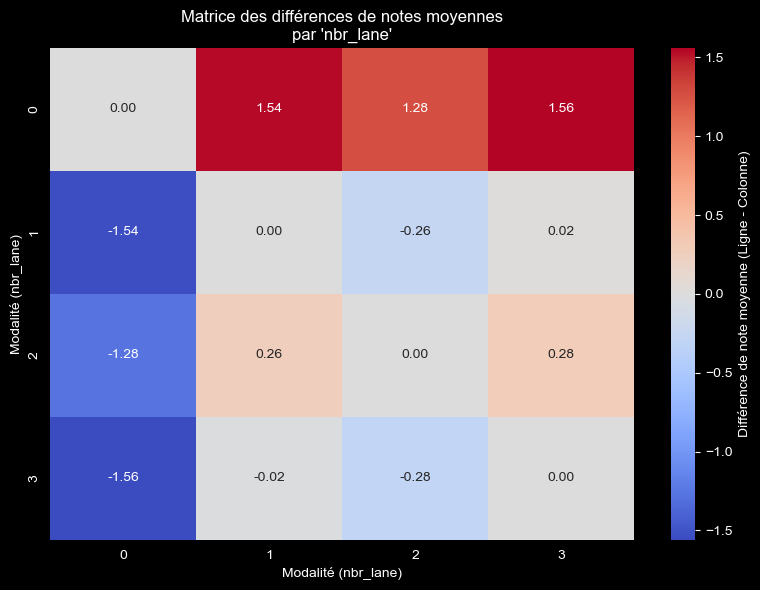

In [62]:
heat_map("nbr_lane")

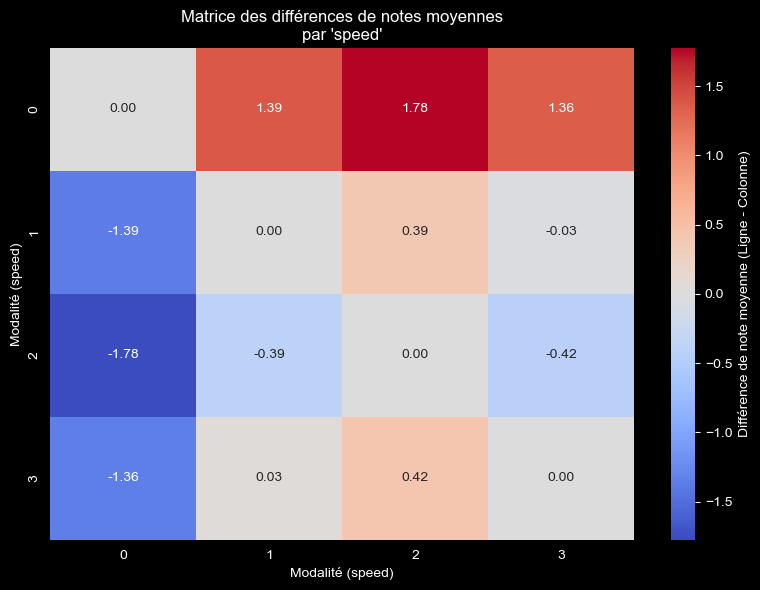

In [63]:
heat_map("speed")

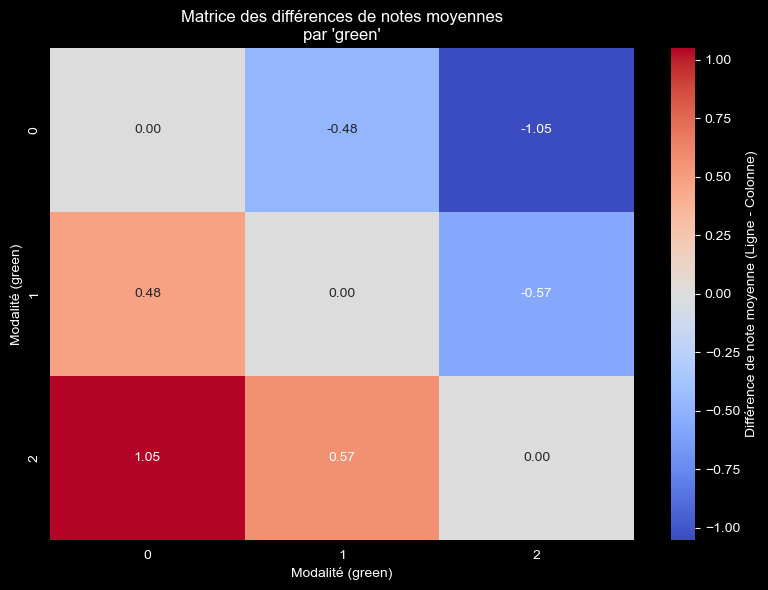

In [64]:
heat_map("green")

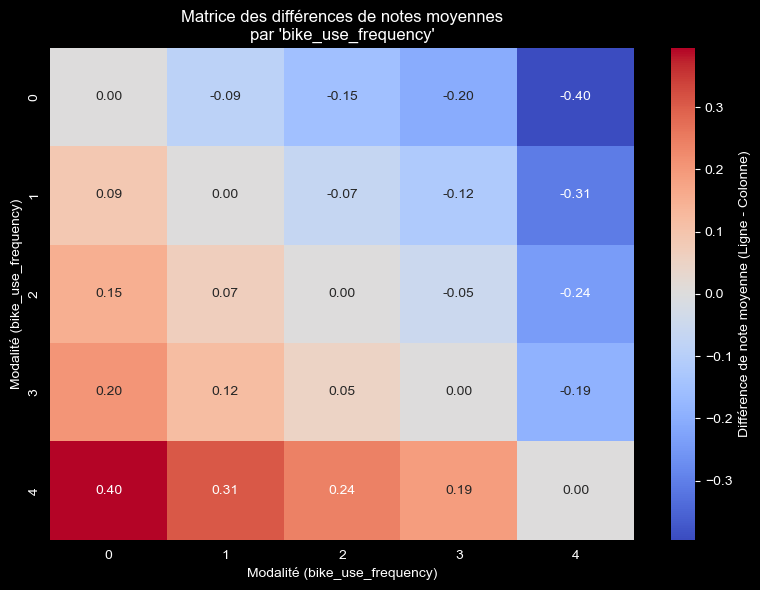

In [65]:
heat_map("bike_use_frequency")

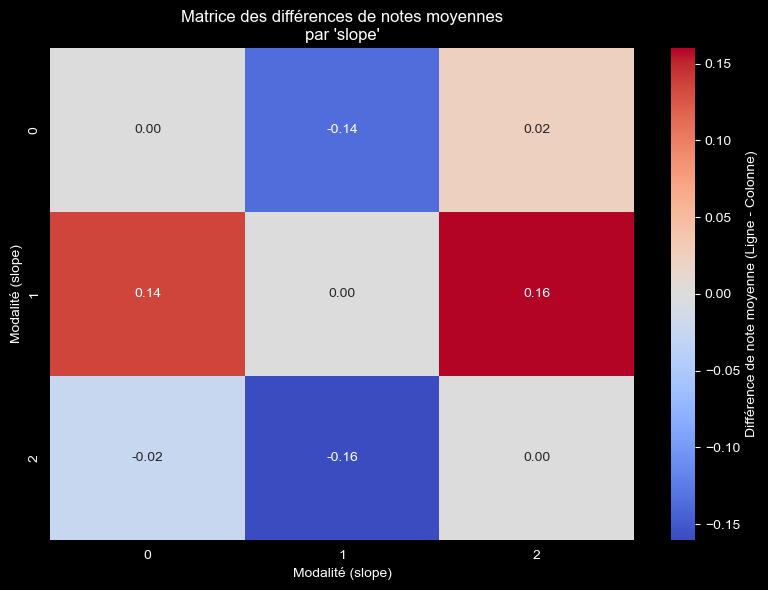

In [67]:
heat_map("slope")

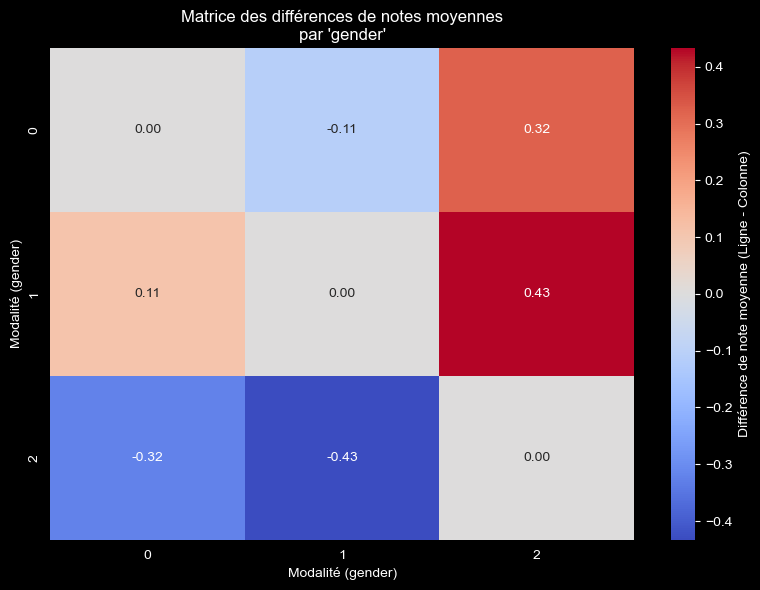

In [66]:
heat_map("gender")

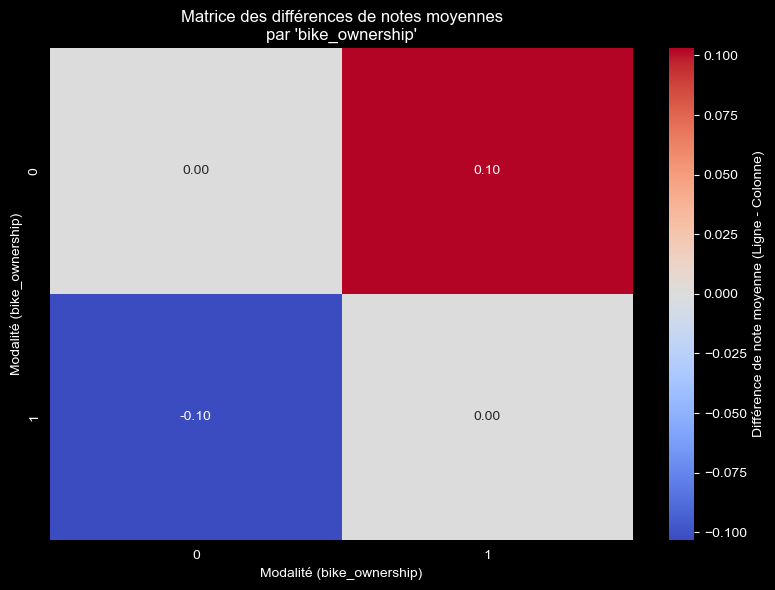

In [68]:
heat_map("bike_ownership")

In [86]:
# 1. Calcul de la moyenne globale de référence pour toutes les notes
global_mean = df['note'].mean()
print(f"Moyenne globale de toutes les notes : {global_mean:.2f}\n")

# 2. Calcul des écarts pour chaque sous-catégorie
records = []

for cat in categories:
    if cat in df.columns:
        # Calcul de la moyenne pour chaque sous-catégorie
        sub_means = df.groupby(cat)['note'].mean()

        for subcat, mean_val in sub_means.items():
            deviation = mean_val - global_mean
            records.append({
                'Category': cat,
                'Subcategory': f"{cat} = {subcat}",
                'Mean_Note': mean_val,
                'Deviation': deviation,
                'Abs_Deviation': abs(deviation)
            })

# Transformation en DataFrame
df_dev = pd.DataFrame(records)

# Tri par l'écart absolu (du plus influent au moins influent)
df_dev = df_dev.sort_values(by='Deviation', ascending=False)



# 4. Affichage d'un tableau récapitulatif textuel dans la console
print("--- Tableau récapitulatif classé par niveau d'influence ---")
print(df_dev[['Subcategory', 'Mean_Note', 'Deviation']].to_string(index=False))

--- Tableau récapitulatif classé par niveau d'influence ---
           Subcategory  Mean_Note  Deviation
              type = 3   4.277966   0.957926
          nbr_lane = 0   4.196126   0.876086
             speed = 0   4.196126   0.876086
             green = 2   3.991525   0.671486
              type = 2   3.991525   0.671486
bike_use_frequency = 4   3.462514   0.142475
             green = 1   3.423729   0.103689
    bike_ownership = 0   3.388235   0.068195
            gender = 1   3.374332   0.054292
  electric_bike = True   3.354724   0.034684
 electric_bike = False   3.306574  -0.013465
    bike_ownership = 1   3.285068  -0.034972
bike_use_frequency = 3   3.271493  -0.048547
            gender = 0   3.263529  -0.056510
bike_use_frequency = 2   3.221289  -0.098751
bike_use_frequency = 1   3.153846  -0.166194
bike_use_frequency = 0   3.067227  -0.252813
              type = 1   2.983051  -0.336989
            gender = 2   2.941176  -0.378863
             green = 0   2.940678  -0.37

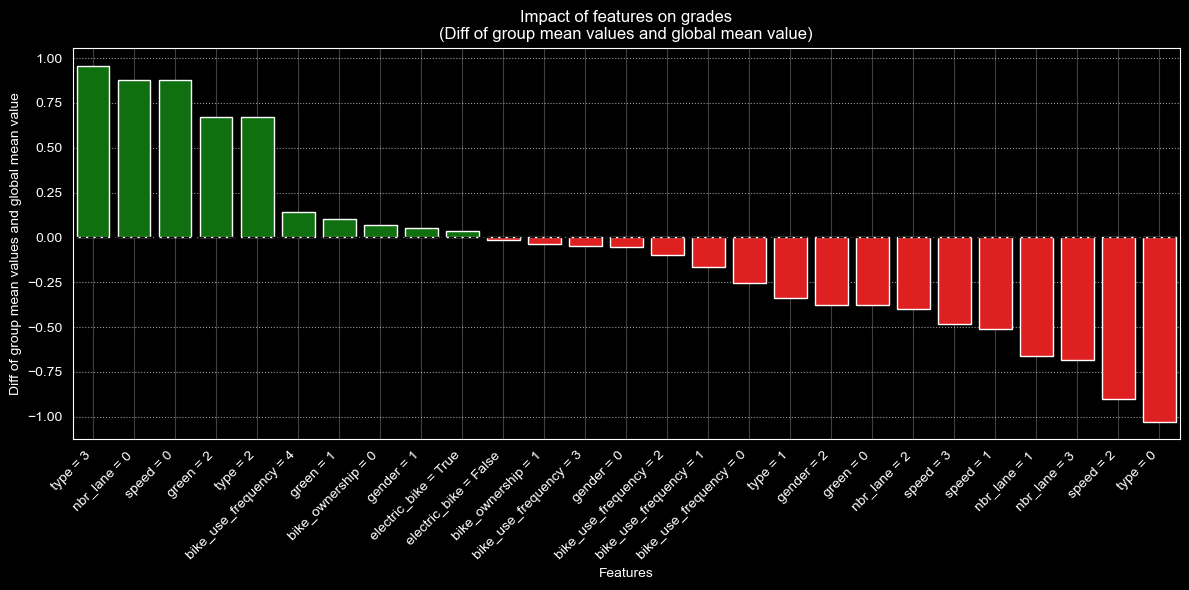

In [97]:
# 3. Création du Bar Plot
plt.figure(figsize=(12, 6))

# Couleur conditionnelle : Vert si la note est supérieure à la moyenne, Rouge si elle est inférieure
colors = ['green' if dev > 0 else 'red' for dev in df_dev['Deviation']]

ax = sns.barplot(
    data=df_dev,
    x='Subcategory',
    y='Deviation',
    palette=colors
)

plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title("Impact of features on grades\n(Diff of group mean values and global mean value)", fontsize=12)
plt.xlabel("Features", fontsize=10)
plt.ylabel("Diff of group mean values and global mean value", fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.grid(axis='x', linestyle='solid', alpha=0.25)
plt.tight_layout()
plt.show()